# Purpose

This file uses the survey response data from "survey_responses.csv" in the data
to create graphs that show relationships between different demographcis and
their responses. All of these output files are in the visualizations folder.


In [23]:
import pandas as pd

In [24]:
responses = pd.read_csv("../data/survey_responses.csv")


def parse_colleges(row):
    college_list = row["colleges"].split(", ")
    row["is_cas"] = "College of Arts & Sciences" in college_list
    row["is_com"] = "College of Communication" in college_list
    row["is_eng"] = "College of Engineering" in college_list
    row["is_cfa"] = "College of Fine Arts" in college_list
    row["is_cgs"] = "College of General Studies" in college_list
    row["is_cds"] = "Faculty of Computing and Data Sciences" in college_list
    row["is_par"] = "Pardee School of Global Studies" in college_list
    row["is_sar"] = "Sargent College of Health" in college_list
    row["is_sha"] = "School of Hospitality Administration" in college_list
    row["is_qst"] = "Questrom School of Business" in college_list
    row["is_oth"] = "Other (including graduate programs)" in college_list
    return row


def clean_data(df):
    df.drop(columns="Timestamp", inplace=True)

    # renames columns
    df.rename(
        columns={
            "What is your year of graduation?": "grad_years",
            "In what college(s) do you study at Boston University?": "colleges",
            "How would you describe your gender?": "gender",
            "How would you describe your race?": "race",
            "How many hours of physical activity do you do per week?": "activity_level",
            "How many times per week do you use a water-filling station to refill your water bottle?": "station_refills",
            "How easily accessible are the water-filling stations on campus?": "station_accessibility",
            "How many times per week do you purchase bottled water on campus?": "purchase_count",
            "How many times per week do you use a publicly accessible kitchen sink on campus to refill your water bottle?": "kitchen_refills",
            "How easily accessible are the public kitchen sinks on campus?": "kitchen_accessibility",
            "Did you know that the tap water in Boston is among the cleanest and safest in the country, and can be drank without a filter?": "tap_awareness",
            "Given this new information, are you more likely to use kitchen sinks to refill your water bottle?": "kitchen_change",
        },
        inplace=True,
    )

    # maps responses to numerical values
    value_mappings = {
        "grad_years": {"2024": 0, "2025": 1, "2026": 2, "2027": 3, "2028+": 4},
        "gender": {
            "Woman": 0,
            "Man": 1,
            "Transgender": 2,
            "Gender Neutral": 3,
            "Other": 4,
            "I prefer not to respond": 5,
        },
        "race": {
            "Asian": 0,
            "Black or African American": 1,
            "Hispanic/Latino": 2,
            "Indigenous": 3,
            "Middle Eastern/North African": 4,
            "Native Hawaiian or Pacific Islander": 5,
            "White": 6,
            "Another race or ethnicity": 7,
            "I prefer not to respond": 8,
        },
        "activity_level": {"0": 0, "1-2": 1, "3-5": 2, "6+": 3},
        "station_refills": {"0": 0, "1-2": 1, "3-5": 2, "6+": 3},
        "station_accessibility": {
            "It is hard to find one.": 0,
            "It takes too long to find one.": 1,
            "It takes some time to find one, but it is manageable.": 2,
            "It is easy to find one.": 3,
        },
        "purchase_count": {"0": 0, "1-2": 1, "3-5": 2, "6+": 3},
        "kitchen_refills": {"0": 0, "1-2": 1, "3-5": 2, "6+": 3},
        "kitchen_accessibility": {
            "It is hard to find one.": 0,
            "It takes too long to find one.": 1,
            "It takes some time to find one, but it is manageable.": 2,
            "It is easy to find one.": 3,
        },
        "tap_awareness": {"No": 0, "Yes": 1},
        "kitchen_change": {"No": 0, "Yes": 1, "I already use the kitchen sinks": 2},
        "is_cas": {False: 0, True: 1},
        "is_com": {False: 0, True: 1},
        "is_eng": {False: 0, True: 1},
        "is_cfa": {False: 0, True: 1},
        "is_cgs": {False: 0, True: 1},
        "is_cds": {False: 0, True: 1},
        "is_par": {False: 0, True: 1},
        "is_sar": {False: 0, True: 1},
        "is_sha": {False: 0, True: 1},
        "is_qst": {False: 0, True: 1},
        "is_oth": {False: 0, True: 1},
    }

    df = df.apply(parse_colleges, axis=1)

    responses_num = pd.DataFrame()

    for column in value_mappings:
        responses_num[column] = df[column].map(value_mappings[column])

    return df, responses_num


cleaned_responses, responses_num = clean_data(responses)

In [25]:
# prints the counts of each response
response_counts = {
    column: responses[column].value_counts() for column in responses.columns
}
print(response_counts)

{'grad_years': grad_years
2025     22
2027     13
2026     12
2024      2
2028+     2
Name: count, dtype: int64, 'colleges': colleges
College of Arts & Sciences                                                                         11
Faculty of Computing and Data Sciences                                                              8
Questrom School of Business                                                                         8
College of Engineering                                                                              8
College of Arts & Sciences, Faculty of Computing and Data Sciences                                  5
Other (including graduate programs)                                                                 2
Sargent College of Health                                                                           2
College of Arts & Sciences, Questrom School of Business                                             1
College of Communication                          

In [26]:
print(cleaned_responses.head())

  grad_years                                           colleges gender   race  \
0       2025                Other (including graduate programs)  Woman  Asian   
1       2026             Faculty of Computing and Data Sciences    Man  White   
2       2024                         College of Arts & Sciences    Man  Asian   
3       2026             Faculty of Computing and Data Sciences  Woman  Asian   
4       2025  College of Arts & Sciences, Questrom School of...  Woman  White   

  activity_level station_refills  \
0            1-2               0   
1            1-2               0   
2            1-2               0   
3            3-5              6+   
4            1-2              6+   

                               station_accessibility purchase_count  \
0  It takes some time to find one, but it is mana...              0   
1  It takes some time to find one, but it is mana...            3-5   
2  It takes some time to find one, but it is mana...            1-2   
3  It takes 

In [27]:
print(responses_num.head())

   grad_years  gender  race  activity_level  station_refills  \
0           1       0   0.0               1                0   
1           2       1   6.0               1                0   
2           0       1   0.0               1                0   
3           2       0   0.0               2                3   
4           1       0   6.0               1                3   

   station_accessibility  purchase_count  kitchen_refills  \
0                      2               0                0   
1                      2               2                0   
2                      2               1                0   
3                      2               0                1   
4                      3               0                0   

   kitchen_accessibility  tap_awareness  ...  is_com  is_eng  is_cfa  is_cgs  \
0                      1              0  ...       0       0       0       0   
1                      1              1  ...       0       0       0       0   
2       

In [28]:
# diagram showing relationship betweem attributes
value_descriptions = {
    "grad_years": {0: "2024", 1: "2025", 2: "2026", 3: "2027", 4: "2028+"},
    "gender": {
        0: "Woman",
        1: "Man",
        2: "Transgender",
        3: "Gender Neutral",
        4: "Other",
        5: "Prefer not to respond",
    },
    "race": {
        0: "Asian",
        1: "Black or African American",
        2: "Hispanic/Latino",
        3: "Indigenous",
        4: "Middle Eastern/North African",
        5: "Native Hawaiian or Pacific Islander",
        6: "White",
        7: "Another race or ethnicity",
        8: "Prefer not to respond",
    },
    "activity_level": {0: "0", 1: "1-2", 2: "3-5", 3: "6+"},
    "station_refills": {0: "0", 1: "1-2", 2: "3-5", 3: "6+"},
    "station_accessibility": {
        0: "Hard to find",
        1: "Takes too long to find",
        2: "Takes some time but manageable",
        3: "Easy to find",
    },
    "purchase_count": {0: "0", 1: "1-2", 2: "3-5", 3: "6+"},
    "kitchen_refills": {0: "0", 1: "1-2", 2: "3-5", 3: "6+"},
    "kitchen_accessibility": {
        0: "Hard to find",
        1: "Takes too long to find",
        2: "Takes some time but manageable",
        3: "Easy to find",
    },
    "tap_awareness": {0: "No", 1: "Yes"},
    "kitchen_change": {0: "No", 1: "Yes", 2: "Already use kitchen sinks"},
    "is_cas": {0: "No", 1: "Yes"},
    "is_com": {0: "No", 1: "Yes"},
    "is_eng": {0: "No", 1: "Yes"},
    "is_cfa": {0: "No", 1: "Yes"},
    "is_cgs": {0: "No", 1: "Yes"},
    "is_cds": {0: "No", 1: "Yes"},
    "is_par": {0: "No", 1: "Yes"},
    "is_sar": {0: "No", 1: "Yes"},
    "is_sha": {0: "No", 1: "Yes"},
    "is_qst": {0: "No", 1: "Yes"},
    "is_oth": {0: "No", 1: "Yes"},
}

responses_num_renamed = responses_num.copy()

for column, mapping in value_descriptions.items():
    responses_num_renamed[column] = responses_num[column].map(mapping)

responses_num_renamed.head()

,grad_years,gender,race,activity_level,station_refills,station_accessibility,purchase_count,kitchen_refills,kitchen_accessibility,tap_awareness,...,is_com,is_eng,is_cfa,is_cgs,is_cds,is_par,is_sar,is_sha,is_qst,is_oth
0,2025,Woman,Asian,1-2,0,Takes some time but manageable,0,0,Takes too long to find,No,...,No,No,No,No,No,No,No,No,No,Yes
1,2026,Man,White,1-2,0,Takes some time but manageable,3-5,0,Takes too long to find,Yes,...,No,No,No,No,Yes,No,No,No,No,No
2,2024,Man,Asian,1-2,0,Takes some time but manageable,1-2,0,Hard to find,No,...,No,No,No,No,No,No,No,No,No,No
3,2026,Woman,Asian,3-5,6+,Takes some time but manageable,0,1-2,Takes too long to find,No,...,No,No,No,No,Yes,No,No,No,No,No
4,2025,Woman,White,1-2,6+,Easy to find,0,0,Hard to find,Yes,...,No,No,No,No,No,No,No,No,Yes,No


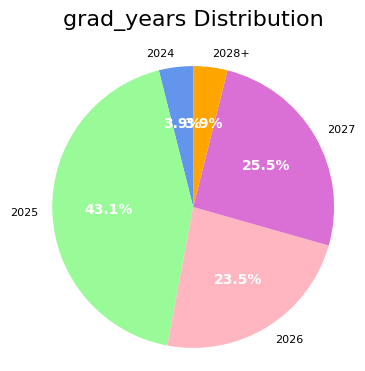

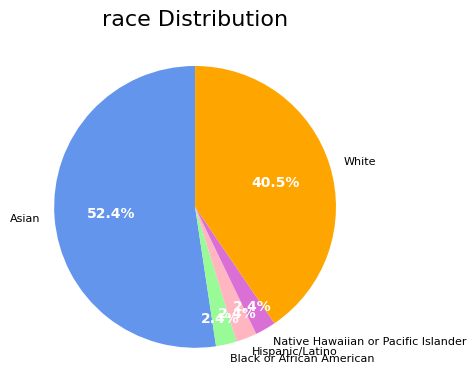

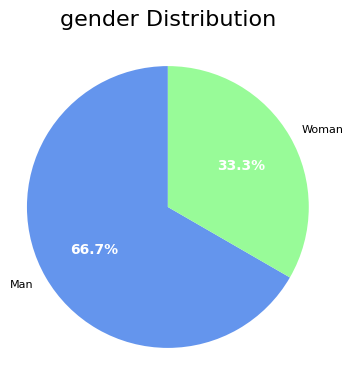

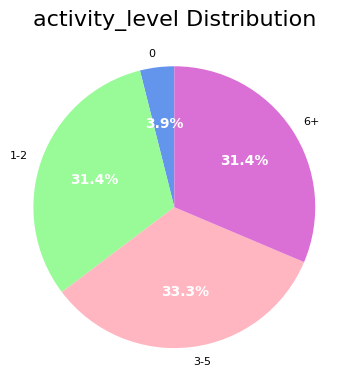

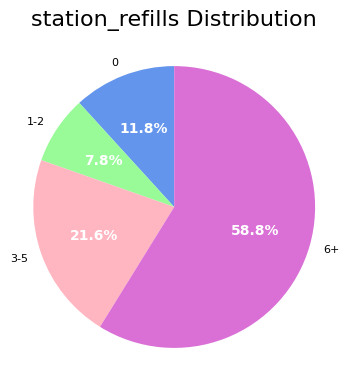

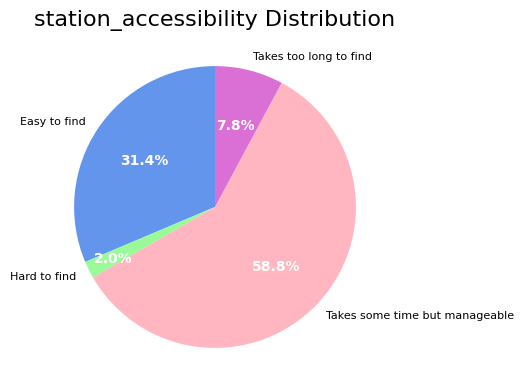

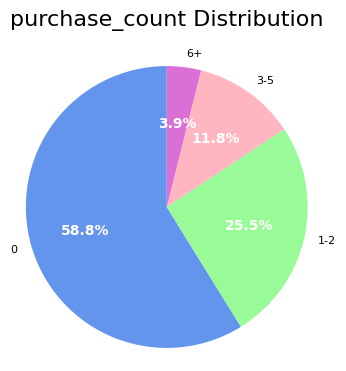

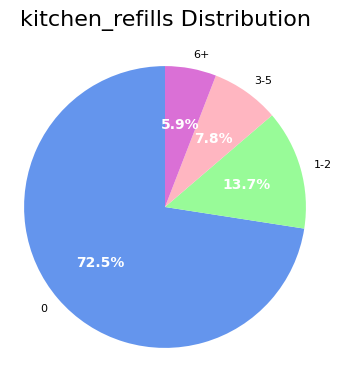

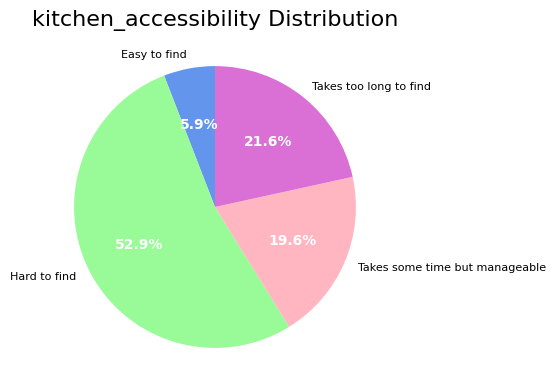

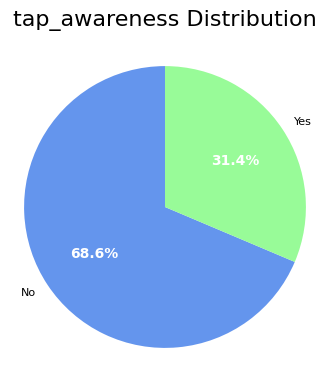

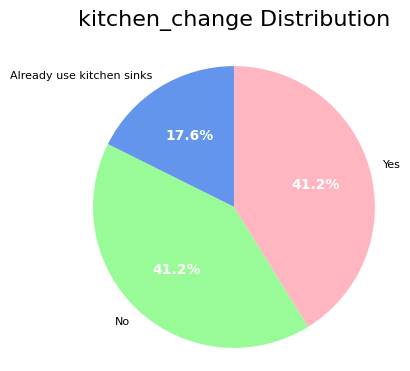

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def plot_selected_pie_charts(data, columns):
    # creates pie charts of the responses
    custom_colors = ["#6495ED", "#98FB98", "#FFB6C1", "#DA70D6", "#FFA500"]
    max_categories = max(data[col].nunique() for col in columns)
    colors = plt.cm.tab20(np.linspace(0, 1, max_categories))

    for column in columns:
        fig, ax = plt.subplots(figsize=(4, 4))
        counts = data[column].value_counts().sort_index()
        wedges, texts, autotexts = ax.pie(
            counts,
            labels=counts.index,
            autopct="%1.1f%%",
            startangle=90,
            colors=custom_colors[: len(counts)],
            textprops={"fontsize": 8},
        )

        for text, wedge in zip(autotexts, wedges):
            if wedge.theta2 - wedge.theta1 < 10:
                x, y = text.get_position()
                text.set_position((1.35 * x, 1.35 * y))

        plt.setp(autotexts, size=10, weight="bold", color="white")
        ax.set_title(f"{column} Distribution", fontsize=16, pad=20)
        ax.axis("equal")
        plt.savefig(f"../visualizations/extension/{column}_pie_charts.png")
        # plt.show()


plot_selected_pie_charts(
    responses_num_renamed,
    [
        "grad_years",
        "race",
        "gender",
        "activity_level",
        "station_refills",
        "station_accessibility",
        "purchase_count",
        "kitchen_refills",
        "kitchen_accessibility",
        "tap_awareness",
        "kitchen_change",
    ],
)

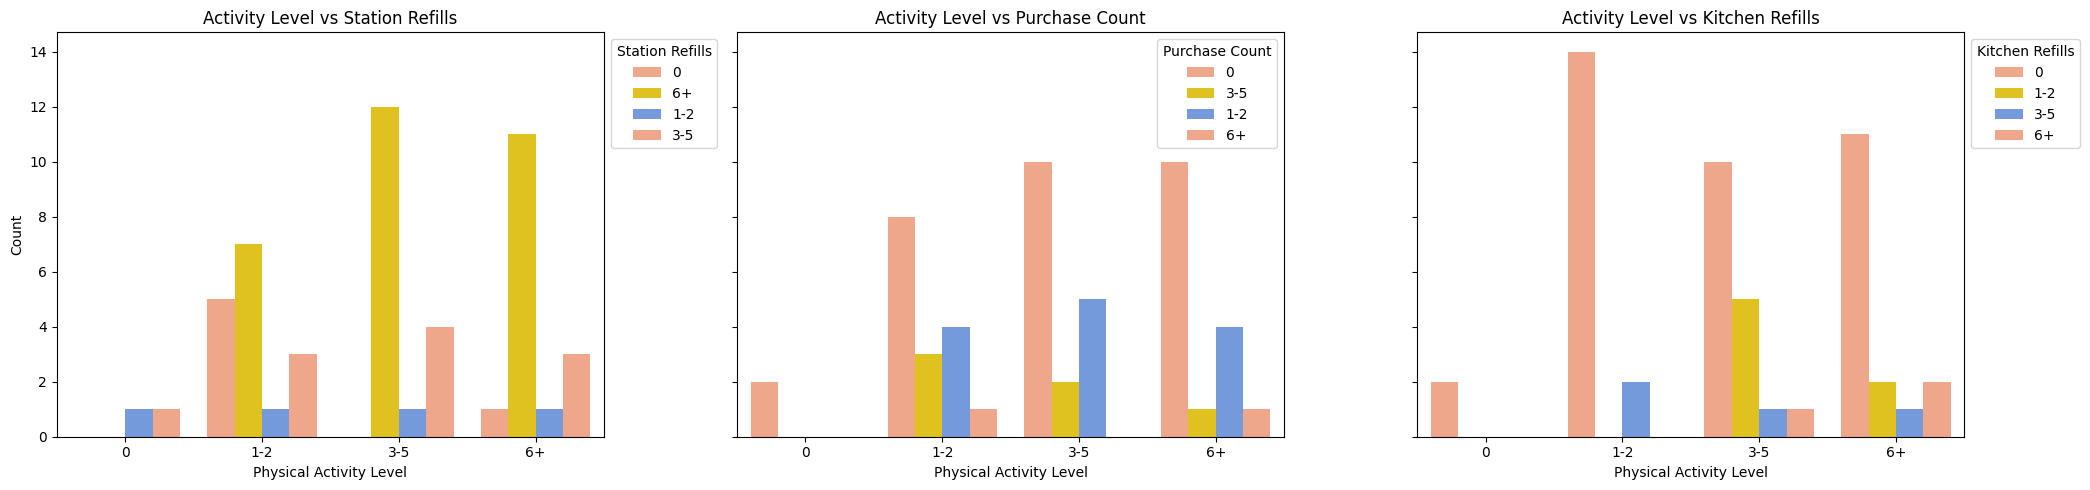

In [30]:
import seaborn as sns


def plot_activity_and_water_bars(data):
    # plots graphs of activity level vs water usage
    fig, axes = plt.subplots(1, 3, figsize=(21, 5), sharey=True)
    activity_order = ["0", "1-2", "3-5", "6+"]
    color_palette = ["#FFA07A", "#FFD700", "#6495ED"]

    ax1 = sns.countplot(
        x="activity_level",
        hue="station_refills",
        data=data,
        order=activity_order,
        palette=color_palette,
        ax=axes[0],
    )
    ax1.set_title("Activity Level vs Station Refills")
    ax1.set_xlabel("Physical Activity Level")
    ax1.set_ylabel("Count")
    ax1.legend(title="Station Refills", bbox_to_anchor=(1, 1))

    ax2 = sns.countplot(
        x="activity_level",
        hue="purchase_count",
        data=data,
        order=activity_order,
        palette=color_palette,
        ax=axes[1],
    )
    ax2.set_title("Activity Level vs Purchase Count")
    ax2.set_xlabel("Physical Activity Level")
    ax2.set_ylabel("")
    ax2.legend(title="Purchase Count", bbox_to_anchor=(1, 1))

    ax3 = sns.countplot(
        x="activity_level",
        hue="kitchen_refills",
        data=data,
        order=activity_order,
        palette=color_palette,
        ax=axes[2],
    )
    ax3.set_title("Activity Level vs Kitchen Refills")
    ax3.set_xlabel("Physical Activity Level")
    ax3.set_ylabel("")
    ax3.legend(title="Kitchen Refills", bbox_to_anchor=(1, 1))

    plt.tight_layout()
    plt.savefig("../visualizations/extension/activity_and_water_bar_charts.png")
    plt.show()


plot_activity_and_water_bars(responses_num_renamed)

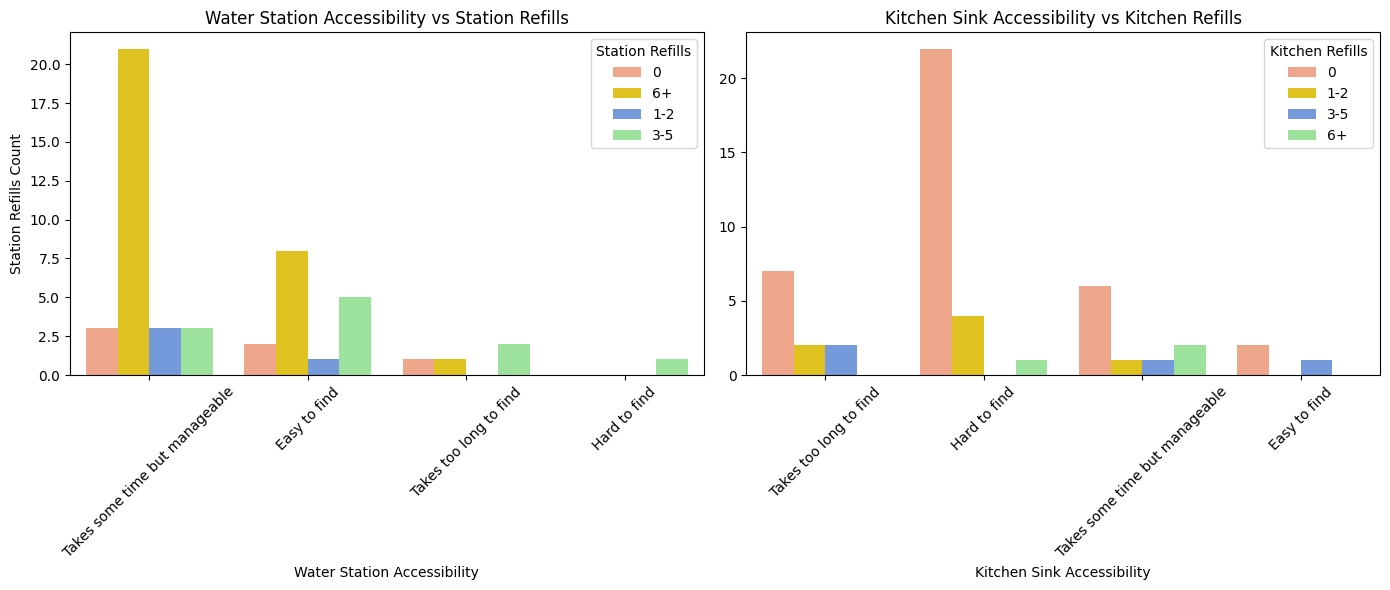

In [31]:
# responses_num_renamed['station_accessibility'] = responses['station_accessibility']
# responses_num_renamed['kitchen_accessibility'] = responses['kitchen_accessibility']

color_palette = ["#FFA07A", "#FFD700", "#6495ED", "#90EE90"]


def plot_accessibility_and_refills_bars(data):
    # plot graphs of accessibility levels vs refills
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    ax1 = sns.countplot(
        x="station_accessibility",
        hue="station_refills",
        data=data,
        palette=color_palette,
        ax=axes[0],
    )
    ax1.set_title("Water Station Accessibility vs Station Refills")
    ax1.set_xlabel("Water Station Accessibility")
    ax1.set_ylabel("Station Refills Count")
    ax1.legend(title="Station Refills")
    ax1.tick_params(axis="x", rotation=45)

    ax2 = sns.countplot(
        x="kitchen_accessibility",
        hue="kitchen_refills",
        data=data,
        palette=color_palette,
        ax=axes[1],
    )
    ax2.set_title("Kitchen Sink Accessibility vs Kitchen Refills")
    ax2.set_xlabel("Kitchen Sink Accessibility")
    ax2.set_ylabel("")
    ax2.legend(title="Kitchen Refills")
    ax2.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.savefig("../visualizations/extension/accessibility_refills_bar_charts.png")
    plt.show()


plot_accessibility_and_refills_bars(responses_num_renamed)

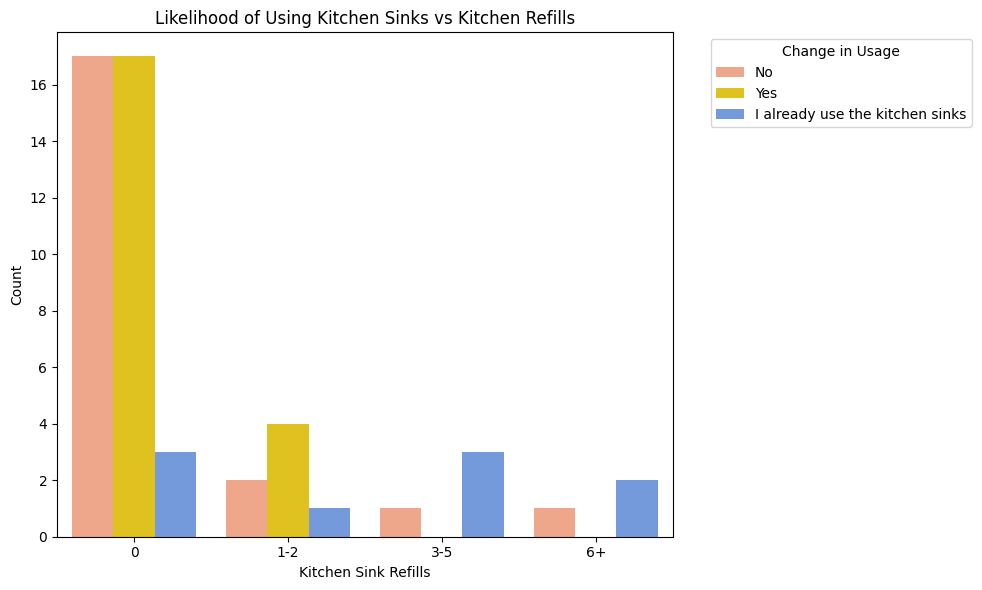

In [32]:
color_palette_change = ["#FFA07A", "#FFD700", "#6495ED"]

responses_num_renamed["kitchen_change"] = responses["kitchen_change"]

plt.figure(figsize=(10, 6))
ax = sns.countplot(
    x="kitchen_refills",
    hue="kitchen_change",
    data=responses_num_renamed,
    palette=color_palette_change,
)
ax.set_title("Likelihood of Using Kitchen Sinks vs Kitchen Refills")
ax.set_xlabel("Kitchen Sink Refills")
ax.set_ylabel("Count")
ax.legend(title="Change in Usage", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.savefig("../visualizations/extension/kitchen_usage_likelihood_charts.png")
plt.show()